In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import RESULTS_DIR
from src.models import MODEL_NAMES
from src.stats import wilcoxon_p, corrected_ttest_p, holm, cliffs_delta, cliffs_magnitude
from src.plotting import use_style, save, MODEL_COLORS, TEXT

use_style()
cv = pd.read_csv(RESULTS_DIR / "03_cv_folds.csv")
cv_summary = pd.read_csv(RESULTS_DIR / "03_cv_summary.csv", index_col=0)
test_scores = pd.read_csv(RESULTS_DIR / "03_test_scores.csv", index_col=0)
scores = cv.pivot(index="fold", columns="model", values="macro_f1")[MODEL_NAMES]
best = scores.drop(columns="Dummy").mean().idxmax()
print(best)

XGBoost


In [2]:
rows = []
for name in [m for m in MODEL_NAMES if m != best]:
    delta = cliffs_delta(scores[best], scores[name])
    rows.append({"model": name, "mean_difference": (scores[best] - scores[name]).mean(),
                 "wilcoxon_p": wilcoxon_p(scores[best], scores[name]),
                 "corrected_t_p": corrected_ttest_p(scores[best], scores[name], 0.1),
                 "cliffs_delta": delta, "magnitude": cliffs_magnitude(delta)})
tests = pd.DataFrame(rows).set_index("model")
tests["wilcoxon_p_holm"] = holm(tests["wilcoxon_p"])
tests["corrected_t_p_holm"] = holm(tests["corrected_t_p"])
tests["significant"] = tests["wilcoxon_p_holm"] < 0.05
tests.to_csv(RESULTS_DIR / "04_significance_vs_best.csv")
tests.round(4)

,mean_difference,wilcoxon_p,corrected_t_p,cliffs_delta,magnitude,wilcoxon_p_holm,corrected_t_p_holm,significant
model,,,,,,,,
Dummy,0.5634,0.002,0.0000,1.0,large,0.0098,0.0000,True
LogReg,0.1703,0.002,0.0000,1.0,large,0.0098,0.0000,True
kNN,0.1402,0.002,0.0000,1.0,large,0.0098,0.0000,True
NaiveBayes,0.4011,0.002,0.0000,1.0,large,0.0098,0.0000,True
RandomForest,0.0131,0.002,0.0007,0.5,large,0.0098,0.0007,True


In [3]:
pairs = [(a, b) for i, a in enumerate(MODEL_NAMES) for b in MODEL_NAMES[i + 1:]]
adjusted = holm([wilcoxon_p(scores[a], scores[b]) for a, b in pairs])
pairwise = pd.DataFrame(np.nan, index=MODEL_NAMES, columns=MODEL_NAMES)
for (a, b), p in zip(pairs, adjusted):
    pairwise.loc[a, b] = pairwise.loc[b, a] = p
pairwise.to_csv(RESULTS_DIR / "04_pairwise_wilcoxon_holm.csv")
pairwise.round(4)

,Dummy,LogReg,kNN,NaiveBayes,RandomForest,XGBoost
Dummy,NaN,0.0293,0.0293,0.0293,0.0293,0.0293
LogReg,0.0293,NaN,0.0293,0.0293,0.0293,0.0293
kNN,0.0293,0.0293,NaN,0.0293,0.0293,0.0293
NaiveBayes,0.0293,0.0293,0.0293,NaN,0.0293,0.0293
RandomForest,0.0293,0.0293,0.0293,0.0293,NaN,0.0293
XGBoost,0.0293,0.0293,0.0293,0.0293,0.0293,NaN


In [4]:
def mean_std(model, metric, digits=3):
    return f"{cv_summary.loc[model, metric + '_mean']:.{digits}f} ± {cv_summary.loc[model, metric + '_std']:.{digits}f}"

order = cv_summary.loc[MODEL_NAMES, "macro_f1_mean"].sort_values(ascending=False).index
table = pd.DataFrame(index=order)
for metric in ["macro_f1", "balanced_accuracy", "accuracy", "roc_auc", "brier", "ece", "detection_rate", "false_alarm_rate"]:
    table[metric] = [mean_std(m, metric) for m in order]
table["test_macro_f1"] = test_scores.loc[order, "macro_f1"].round(3)
table["test_detection_rate"] = test_scores.loc[order, "detection_rate"].round(3)
table["test_false_alarm_rate"] = test_scores.loc[order, "false_alarm_rate"].round(3)
table["train_time_s"] = [mean_std(m, "fit_s", 1) for m in order]
table["inference_ms_per_1k"] = [mean_std(m, "predict_ms_per_1k", 1) for m in order]
table["vs_best"] = ["reference" if m == best else
                    f"p={tests.loc[m, 'wilcoxon_p_holm']:.3g}, delta={tests.loc[m, 'cliffs_delta']:.2f}" for m in order]
table.to_csv(RESULTS_DIR / "04_benchmark_table.csv")
table

,macro_f1,balanced_accuracy,accuracy,roc_auc,brier,ece,detection_rate,false_alarm_rate,test_macro_f1,test_detection_rate,test_false_alarm_rate,train_time_s,inference_ms_per_1k,vs_best
model,,,,,,,,,,,,,,
XGBoost,0.628 ± 0.014,0.693 ± 0.017,0.795 ± 0.004,0.973 ± 0.002,0.261 ± 0.004,0.052 ± 0.004,0.993 ± 0.001,0.164 ± 0.004,0.515,0.996,0.396,65.5 ± 2.9,36.8 ± 4.9,reference
RandomForest,0.615 ± 0.014,0.645 ± 0.020,0.800 ± 0.003,0.869 ± 0.006,0.273 ± 0.004,0.047 ± 0.003,0.991 ± 0.001,0.156 ± 0.003,0.520,0.995,0.387,51.2 ± 0.9,35.3 ± 2.9,"p=0.00977, delta=0.50"
kNN,0.488 ± 0.016,0.473 ± 0.011,0.776 ± 0.004,0.791 ± 0.012,0.309 ± 0.004,0.063 ± 0.003,0.922 ± 0.003,0.086 ± 0.004,0.428,0.957,0.250,0.6 ± 0.1,705.5 ± 42.0,"p=0.00977, delta=1.00"
LogReg,0.458 ± 0.004,0.619 ± 0.008,0.687 ± 0.003,0.947 ± 0.003,0.392 ± 0.003,0.075 ± 0.002,0.998 ± 0.001,0.200 ± 0.005,0.351,0.997,0.423,152.0 ± 13.4,8.6 ± 1.6,"p=0.00977, delta=1.00"
NaiveBayes,0.227 ± 0.008,0.408 ± 0.012,0.478 ± 0.023,0.838 ± 0.009,1.032 ± 0.046,0.513 ± 0.024,0.978 ± 0.004,0.262 ± 0.018,0.233,0.984,0.464,1.1 ± 0.1,19.6 ± 3.0,"p=0.00977, delta=1.00"
Dummy,0.065 ± 0.000,0.100 ± 0.000,0.482 ± 0.000,0.500 ± 0.000,1.037 ± 0.000,0.518 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.062,0.000,0.000,0.4 ± 0.1,3.3 ± 2.7,"p=0.00977, delta=1.00"


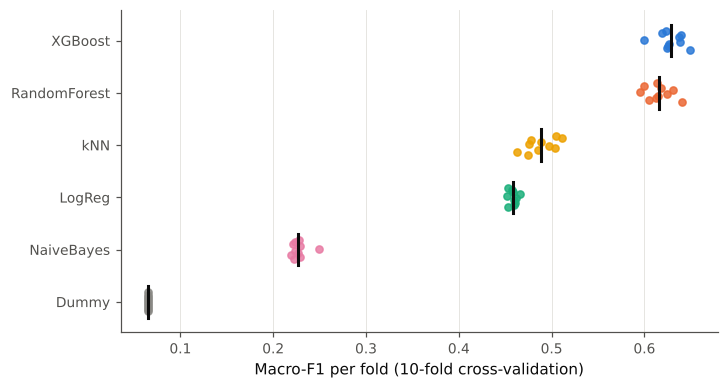

In [5]:
order = scores.mean().sort_values().index
offsets = np.linspace(-0.18, 0.18, len(scores))
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, name in enumerate(order):
    ax.scatter(scores[name], i + offsets, s=22, color=MODEL_COLORS[name], alpha=0.85, zorder=3)
    ax.plot([scores[name].mean()] * 2, [i - 0.3, i + 0.3], color=TEXT, linewidth=2, zorder=4)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("Macro-F1 per fold (10-fold cross-validation)")
ax.grid(axis="y", visible=False)
save(fig, "04_fold_scores.png")
plt.show()